In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets,transforms
from torch.utils.data import DataLoader

In [3]:
transform = transforms.ToTensor()

train_data = datasets.MNIST(root = 'data', train = True,
                            download = True, transform = transform)
test_data = datasets.MNIST(root = 'data', train = False,
                            download = True, transform = transform)

train_loader = DataLoader(train_data, batch_size = 64, shuffle = True)
test_loader = DataLoader(test_data, batch_size = 64, shuffle = False)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.84MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 154kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.45MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.08MB/s]


# FFN

In [6]:
model1 = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784,128),
    nn.ReLU(),
    nn.Linear(128,10)
)

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model1.parameters(),lr = 0.01)

In [8]:
for epochs in range(10):
  for images, labels in train_loader:
    predictions = model1(images)
    loss = loss_fn(predictions,labels)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

  print(f'Epoch{epochs + 1}, Loss: {loss.item():.4f}')

Epoch1, Loss: 0.5020
Epoch2, Loss: 0.2965
Epoch3, Loss: 0.2034
Epoch4, Loss: 0.3797
Epoch5, Loss: 0.2640
Epoch6, Loss: 0.1557
Epoch7, Loss: 0.2385
Epoch8, Loss: 0.4236
Epoch9, Loss: 0.2120
Epoch10, Loss: 0.1799


In [10]:
# Testing
correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        predictions = model1(images)

        predicted = torch.argmax(
            predictions,
            dim=1
        )

        total += labels.size(0)
        correct += (predicted == labels).sum().item()


accuracy = correct / total

print("Test Accuracy:", accuracy)

Test Accuracy: 0.9309


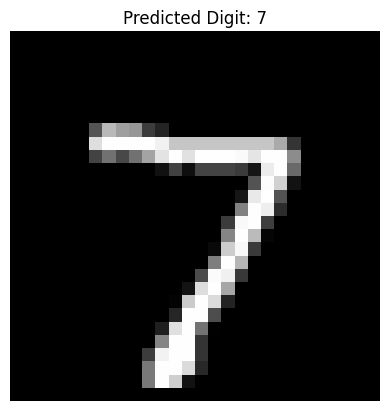

Actual: 7


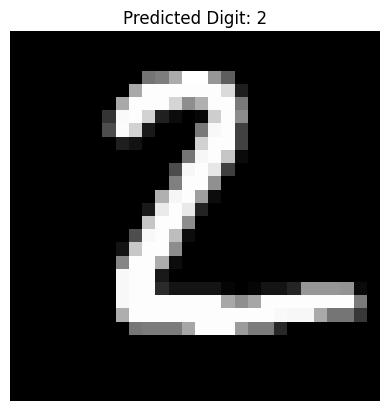

Actual: 2


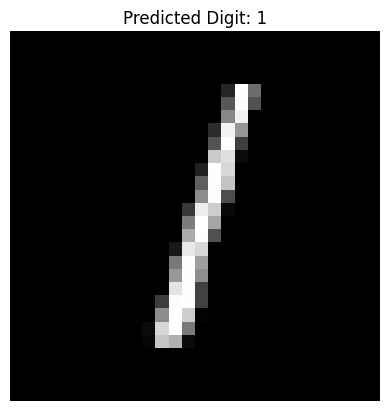

Actual: 1


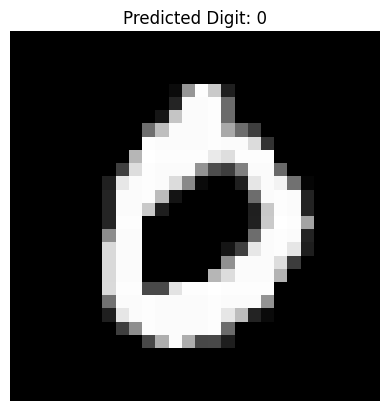

Actual: 0


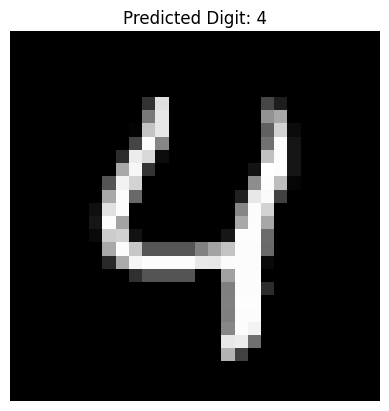

Actual: 4


In [11]:
import matplotlib.pyplot as plt
import torch

model = model1
def predict_image(model, image):

    # Turn off gradient calculation
    with torch.no_grad():

        # Add batch dimension
        image = image.unsqueeze(0)

        # Get model output
        output = model(image)

        # Find the class with highest value
        prediction = torch.argmax(output, dim=1)

    # Display image
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(f"Predicted Digit: {prediction.item()}")
    plt.axis("off")
    plt.show()

    return prediction.item()


for i in range(5):

    image, label = test_data[i]

    prediction = predict_image(model, image)

    print("Actual:", label)

# CNN

In [12]:
model2 = nn.Sequential(
    nn.Conv2d(1,16,3),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Flatten(),
    nn.Linear(16*13*13,10)
)

loss_fn = nn.CrossEntropyLoss()
optimizer = optim.SGD(model2.parameters(),lr = 0.01)

In [13]:
for epochs in range(10):
  for images, labels in train_loader:
    predictions = model2(images)
    loss = loss_fn(predictions,labels)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

  print(f'Epoch{epochs + 1}, Loss: {loss.item():.4f}')

Epoch1, Loss: 0.3003
Epoch2, Loss: 0.3201
Epoch3, Loss: 0.3458
Epoch4, Loss: 0.5081
Epoch5, Loss: 0.3129
Epoch6, Loss: 0.2087
Epoch7, Loss: 0.4709
Epoch8, Loss: 0.2393
Epoch9, Loss: 0.3808
Epoch10, Loss: 0.0581


In [14]:
# Testing
correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        predictions = model2(images)

        predicted = torch.argmax(
            predictions,
            dim=1
        )

        total += labels.size(0)
        correct += (predicted == labels).sum().item()


accuracy = correct / total

print("Test Accuracy:", accuracy)

Test Accuracy: 0.9409


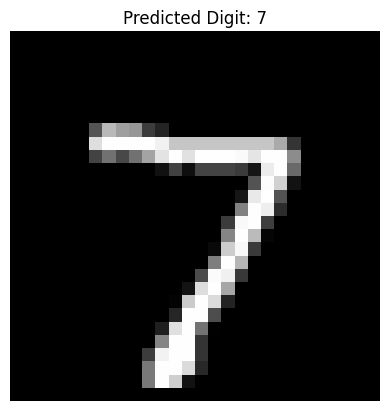

Actual: 7


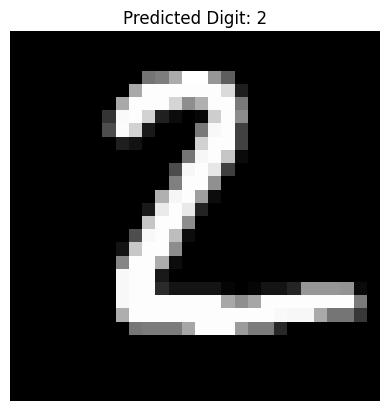

Actual: 2


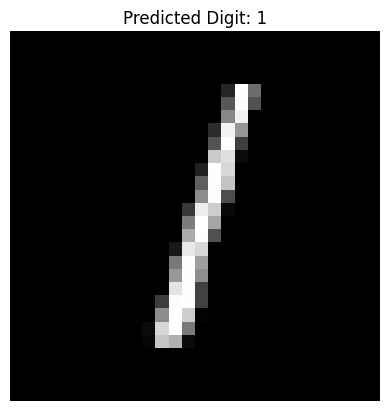

Actual: 1


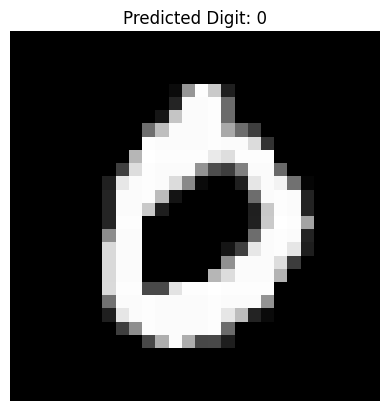

Actual: 0


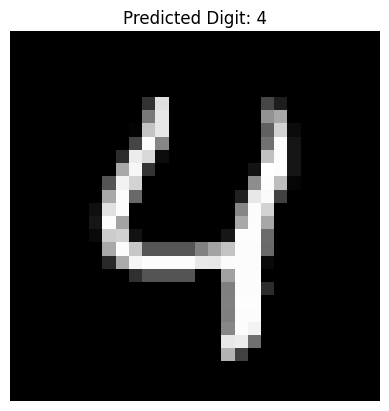

Actual: 4


In [15]:
import matplotlib.pyplot as plt
import torch

model = model2
def predict_image(model, image):

    # Turn off gradient calculation
    with torch.no_grad():

        # Add batch dimension
        image = image.unsqueeze(0)

        # Get model output
        output = model(image)

        # Find the class with highest value
        prediction = torch.argmax(output, dim=1)

    # Display image
    plt.imshow(image.squeeze(), cmap="gray")
    plt.title(f"Predicted Digit: {prediction.item()}")
    plt.axis("off")
    plt.show()

    return prediction.item()


for i in range(5):

    image, label = test_data[i]

    prediction = predict_image(model, image)

    print("Actual:", label)